# Snapget y1 — fine-tune YOLO11 cho xác minh ảnh Daily Quest

Model nhận diện 12 lớp vật thể (cup, bottle, book, chair, potted plant, laptop, keyboard, backpack, clock, umbrella, bicycle, motorcycle).

| Ô | Nội dung |
|---|---|
| 0 | Mount Drive, lấy code, cài thư viện | |
| 1 | COCO 2017 → dataset YOLO 12 lớp | `10` |
| 2 | Giải nén dữ liệu bổ sung | |
| 3 | Gộp dữ liệu, kiểm tra, chia tập | `11` |
| 4 | Fine-tune YOLO11s | `13` |
| 5 | Đánh giá, so sánh các model | `14` |
| 6 | Chọn lớp ra đề quest | `15` |
| 7 | Export ONNX, đưa model lên Hugging Face | `16` |
| 8 | Bảng tổng hợp kết quả | |


In [24]:
# 0a. Drive
from google.colab import drive
drive.mount('/content/drive')
WORK = '/content/drive/MyDrive/snapget-ml'      # dữ liệu gốc + checkpoint (Drive)
YOLO = '/content/yolo'                          # dataset làm việc (đĩa Colab)
EXT = '/content/ext'                            # dữ liệu bổ sung đã giải nén
import os
for d in [WORK, f'{WORK}/data', f'{WORK}/artifacts', YOLO, EXT]:
    os.makedirs(d, exist_ok=True)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [25]:
# 0b. Code + thư viện
%cd /content
!rm -rf datn && git clone --depth 1 https://github.com/HuyenVt001/datn.git datn
%cd /content/datn/ml
!pip install -q -r requirements.txt
!nvidia-smi --query-gpu=name,memory.total --format=csv

/content
Cloning into 'datn'...
remote: Enumerating objects: 824, done.
remote: Counting objects: 100% (824/824), done.
remote: Compressing objects: 100% (734/734), done.
remote: Total 824 (delta 64), reused 469 (delta 27), pack-reused 0 (from 0)
Receiving objects: 100% (824/824), 55.03 MiB | 19.74 MiB/s, done.
Resolving deltas: 100% (64/64), done.
/content/datn/ml
name, memory.total [MiB]
NVIDIA L4, 23034 MiB


## 1. COCO 2017 → YOLO 12 lớp
- Lấy ảnh COCO có chứa 12 lớp (tối đa 2.000 ảnh/lớp) cùng 1.500 ảnh nền không có lớp nào, giữ nguyên box gốc.
- Bổ sung khoảng 20% bản cắt dọc 3:4 mô phỏng ảnh chụp điện thoại. Tập test lấy từ COCO val2017.
- Tải và nén  thành `coco_yolo.zip`

In [26]:
import os
ZIP = f'{WORK}/data/coco_yolo.zip'
if os.path.exists(ZIP):
    !unzip -q -o {ZIP} -d {YOLO}
else:
    !python scripts/10_export_coco_yolo.py --out {YOLO}/coco --max-per-class 2000 --negatives 1500 \
        --test-max 3000 --test-negatives 500 --portrait-frac 0.2
    !cd {YOLO} && zip -q -r {ZIP} coco
!head -40 {YOLO}/coco/stats.json

{
  "val": {
    "images": 1544,
    "portraitCrops": 0,
    "negatives": 0,
    "imagesPerClass": {
      "cup": 321,
      "bottle": 279,
      "book": 247,
      "chair": 389,
      "potted plant": 230,
      "laptop": 231,
      "keyboard": 181,
      "backpack": 221,
      "clock": 190,
      "umbrella": 230,
      "bicycle": 226,
      "motorcycle": 194
    },
    "boxesPerClass": {
      "cup": 741,
      "bottle": 808,
      "book": 1142,
      "chair": 1086,
      "potted plant": 449,
      "laptop": 341,
      "keyboard": 252,
      "backpack": 320,
      "clock": 241,
      "umbrella": 677,
      "bicycle": 519,
      "motorcycle": 479
    }
  },
  "train": {
    "images": 15902,
    "portraitCrops": 2000,
    "negatives": 0,
    "imagesPerClass": {
      "cup": 2785,


## 2. Dữ liệu bổ sung
COCO chủ yếu là ảnh nước ngoài, thiếu nhiều vật thể quen thuộc ở Việt Nam nên nhóm đã xây dựng một bộ dữ liệu bổ sung :
- `snapget_vn_supplement.zip` — tập train bổ sung dữ liệu bản địa: ảnh bối cảnh Việt Nam, nhãn YOLO 12 lớp, chỉ dùng để train.
- `vn.zip` — ảnh tự chụp bằng điện thoại, gồm `train/` và `test/` (cấu trúc theo `ml/DATASET_SPEC.md`). Tập test chỉ gồm ảnh tự chụp; đây là tập dùng để chọn ngưỡng và chọn lớp quest. Khi chưa có, ngưỡng tạm chọn trên tập val.

In [27]:
import os
# ảnh tự chụp (train + test)
!rm -rf {EXT}/vn
if os.path.exists(f'{WORK}/data/vn.zip'):
    print('vn.zip: có')
    !mkdir -p {EXT}/vn && unzip -q -o "{WORK}/data/vn.zip" -d {EXT}/vn
else:
    print('vn.zip: chưa có -> không có tập test ảnh thật, ngưỡng chọn tạm trên val')
# tập train bổ sung dữ liệu bản địa
!rm -rf {EXT}/snapget_vn_supplement
if os.path.exists(f'{WORK}/data/snapget_vn_supplement.zip'):
    print('snapget_vn_supplement.zip: có')
    !unzip -q -o {WORK}/data/snapget_vn_supplement.zip -d {EXT}
else:
    print('snapget_vn_supplement.zip: KHÔNG TÌM THẤY trong WORK/data/')
!ls {EXT}

vn.zip: có
snapget_vn_supplement.zip: có
snapget_vn_supplement  vn


## 3. Gộp dữ liệu, kiểm tra, chia tập
Gộp COCO với dữ liệu bổ sung thành `data.yaml` và danh sách ảnh cho từng tập:
- ảnh bổ sung được lặp ×3 trong tập train để không bị COCO lấn át;
- ảnh test tự chụp chia 40% `real_calib` (chọn ngưỡng) / 60% `real_test` (báo cáo, chọn lớp);
- ảnh train gần trùng ảnh test (dHash) bị loại để tránh rò rỉ.

In [28]:
import glob, os

def find_vn(base):
    # file nén có thể bọc thêm 1–2 tầng thư mục
    cands = [p.rstrip('/') for p in glob.glob(f'{base}/**/', recursive=True)
             if os.path.isdir(os.path.join(p, 'train', 'images')) or os.path.isdir(os.path.join(p, 'test', 'images'))]
    return sorted(cands, key=len)[0] if cands else None

VN_DIR = find_vn(f'{EXT}/vn')
vn = f'--vn {VN_DIR}' if VN_DIR else ''
if os.path.isdir(f'{EXT}/snapget_vn_supplement/train'):
    vn += f' --vn {EXT}/snapget_vn_supplement'
VN_MIN_TRAIN = 100   # số ảnh Việt Nam tối thiểu mỗi lớp trong train
!python scripts/11_merge_external.py --root {YOLO} --coco {YOLO}/coco {vn} --class-map yolo_class_map.yaml \
    --vn-min-train {VN_MIN_TRAIN}
!cp {YOLO}/merge_report.json {WORK}/artifacts/merge_report.json

  ⚠ VN train: gg_backpack_0008.jpg khong co box nao nhung ten khong phai neg/hardneg — kiem tra lai
  ⚠ VN train: gg_backpack_0022.jpg khong co box nao nhung ten khong phai neg/hardneg — kiem tra lai
  ⚠ VN train: gg_backpack_0031.jpg ten lop 'backpack' nhung khong co box lop do
  ⚠ VN train: gg_backpack_0034.jpg khong co box nao nhung ten khong phai neg/hardneg — kiem tra lai
  ⚠ VN train: gg_backpack_0035.jpg khong co box nao nhung ten khong phai neg/hardneg — kiem tra lai
  ⚠ VN train: gg_backpack_0036.jpg khong co box nao nhung ten khong phai neg/hardneg — kiem tra lai
  ⚠ VN train: gg_backpack_0037.jpg khong co box nao nhung ten khong phai neg/hardneg — kiem tra lai
  ⚠ VN train: gg_backpack_0040.jpg khong co box nao nhung ten khong phai neg/hardneg — kiem tra lai
  ⚠ VN train: gg_backpack_0044.jpg khong co box nao nhung ten khong phai neg/hardneg — kiem tra lai
  ⚠ VN train: gg_backpack_0047.jpg khong co box nao nhung ten khong phai neg/hardneg — kiem tra lai
  ⚠ VN train: gg_bac

## 4. Fine-tune
- Khởi tạo từ YOLO11s pretrained COCO; head 80 lớp được cắt còn 12 lớp.
- `imgsz 640`, 40 epoch; dừng sớm nếu 12 epoch liền không cải thiện; 8 epoch cuối tắt mosaic.
- Khi bị Colab ngắt thì chạy lại ô 0 → 1 → 2 → 3 rồi chạy 4b.

In [29]:
# 4a. Train YOLO11s
!python scripts/13_train_yolo.py --data {YOLO}/data.yaml --model yolo11s.pt \
    --project {WORK}/artifacts/yolo --name y1-s --epochs 40 --export-best {WORK}/artifacts/y1-s/best.pt

!! /content/drive/MyDrive/snapget-ml/artifacts/yolo/y1-s da co lan train truoc. Dung --resume de chay tiep, hoac doi --name.


In [30]:
# 4b. Train tiếp từ checkpoint sau khi Colab ngắt
!python scripts/13_train_yolo.py --data {YOLO}/data.yaml --project {WORK}/artifacts/yolo --name y1-s --resume \
    --export-best {WORK}/artifacts/y1-s/best.pt

Resume tu /content/drive/MyDrive/snapget-ml/artifacts/yolo/y1-s/weights/last.pt
New https://pypi.org/project/ultralytics/8.4.220 available 😃 Update with 'pip install -U ultralytics'
Ultralytics 8.4.219 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (NVIDIA L4, 22563MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=46, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=8, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=True, cutmix=0.0, data=/content/yolo/data.yaml, degrees=0.0, deterministic=True, device=, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=40, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.6, hsv_v=0.45, imgsz=640, iou=None, kobj=1.0, line_width=None, lr0=0.0005, lrf=0.01, 

## 5. Đánh giá
Các model được đánh giá trên cùng tập ảnh và cùng cách chọn ngưỡng:
- `yolo11s-coco` — YOLO11s gốc chưa fine-tune (mốc so sánh);
- `y1-s` — model vừa fine-tune;
- `v0` — model MobileNetV3 cũ (nếu còn file `artifacts/v0/model.onnx`).

Hai cấp chỉ số:
- **Detection:** mAP50, mAP50-95 từng lớp, confusion matrix 13×13 (12 lớp + nền).
- **Xác minh ảnh** (đúng với quyết định của app): AP, precision, recall, F1, tỉ lệ từ chối sai, confusion cấp ảnh.

Ngưỡng từng lớp được chọn trên `real_calib` theo nguyên tắc recall cao nhất với precision ≥ 0.80. Đo thêm độ trễ suy luận trên CPU.

In [31]:
import os

def find_weights(name):
    # best.pt sau khi train xong; chưa xong thì lấy best.pt của lượt train đang dở
    for p in (f'{WORK}/artifacts/{name}/best.pt', f'{WORK}/artifacts/yolo/{name}/weights/best.pt'):
        if os.path.exists(p):
            print(f'{name}: {p}' + ('' if p.endswith(f'{name}/best.pt') else '  (chưa train xong)'))
            return p
    print(f'{name}: chưa có -> bỏ qua')

models = '--model yolo11s-coco=yolo11s.pt'
w = find_weights('y1-s')
if w:
    models += f' --model y1-s={w}'
if os.path.exists(f'{WORK}/artifacts/v0/model.onnx'):
    models += f' --classifier v0={WORK}/artifacts/v0/model.onnx'
meta = f'--vn-meta {VN_DIR}/metadata.csv' if VN_DIR and os.path.exists(f'{VN_DIR}/metadata.csv') else ''
!python scripts/14_eval_yolo.py --root {YOLO} --out {WORK}/artifacts/eval {models} {meta} --max-coco 2000

y1-s: /content/drive/MyDrive/snapget-ml/artifacts/y1-s/best.pt
calib (real_calib) 288 anh | real_test 430 | coco_test 1883

===== yolo11s-coco (yolo: yolo11s.pt) =====
nguong: {'cup': 0.2078, 'bottle': 0.689, 'book': 0.2388, 'chair': 0.7509, 'potted plant': 0.2505, 'laptop': 0.3033, 'keyboard': 0.0577, 'backpack': 0.1054, 'clock': 0.1793, 'umbrella': 0.1136, 'bicycle': 0.0927, 'motorcycle': 0.6938}
Ultralytics 8.4.219 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (NVIDIA L4, 22563MiB)
YOLO11s summary (fused): 100 layers, 9,417,444 parameters, 4,644 gradients, 21.4 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 3491.3±548.0 MB/s, size: 293.5 KB)
val: Scanning /content/yolo/vn/labels/test... 430 images, 88 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 430/430 1.5Kit/s 0.3s
val: New cache created: /content/yolo/vn/labels/test.cache
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 27/27 6.7it/s 4.0s
                   all       

Tập: real_test
/content/drive/MyDrive/snapget-ml/artifacts/eval/y1-s/det_real_test/confusion_matrix_normalized.png


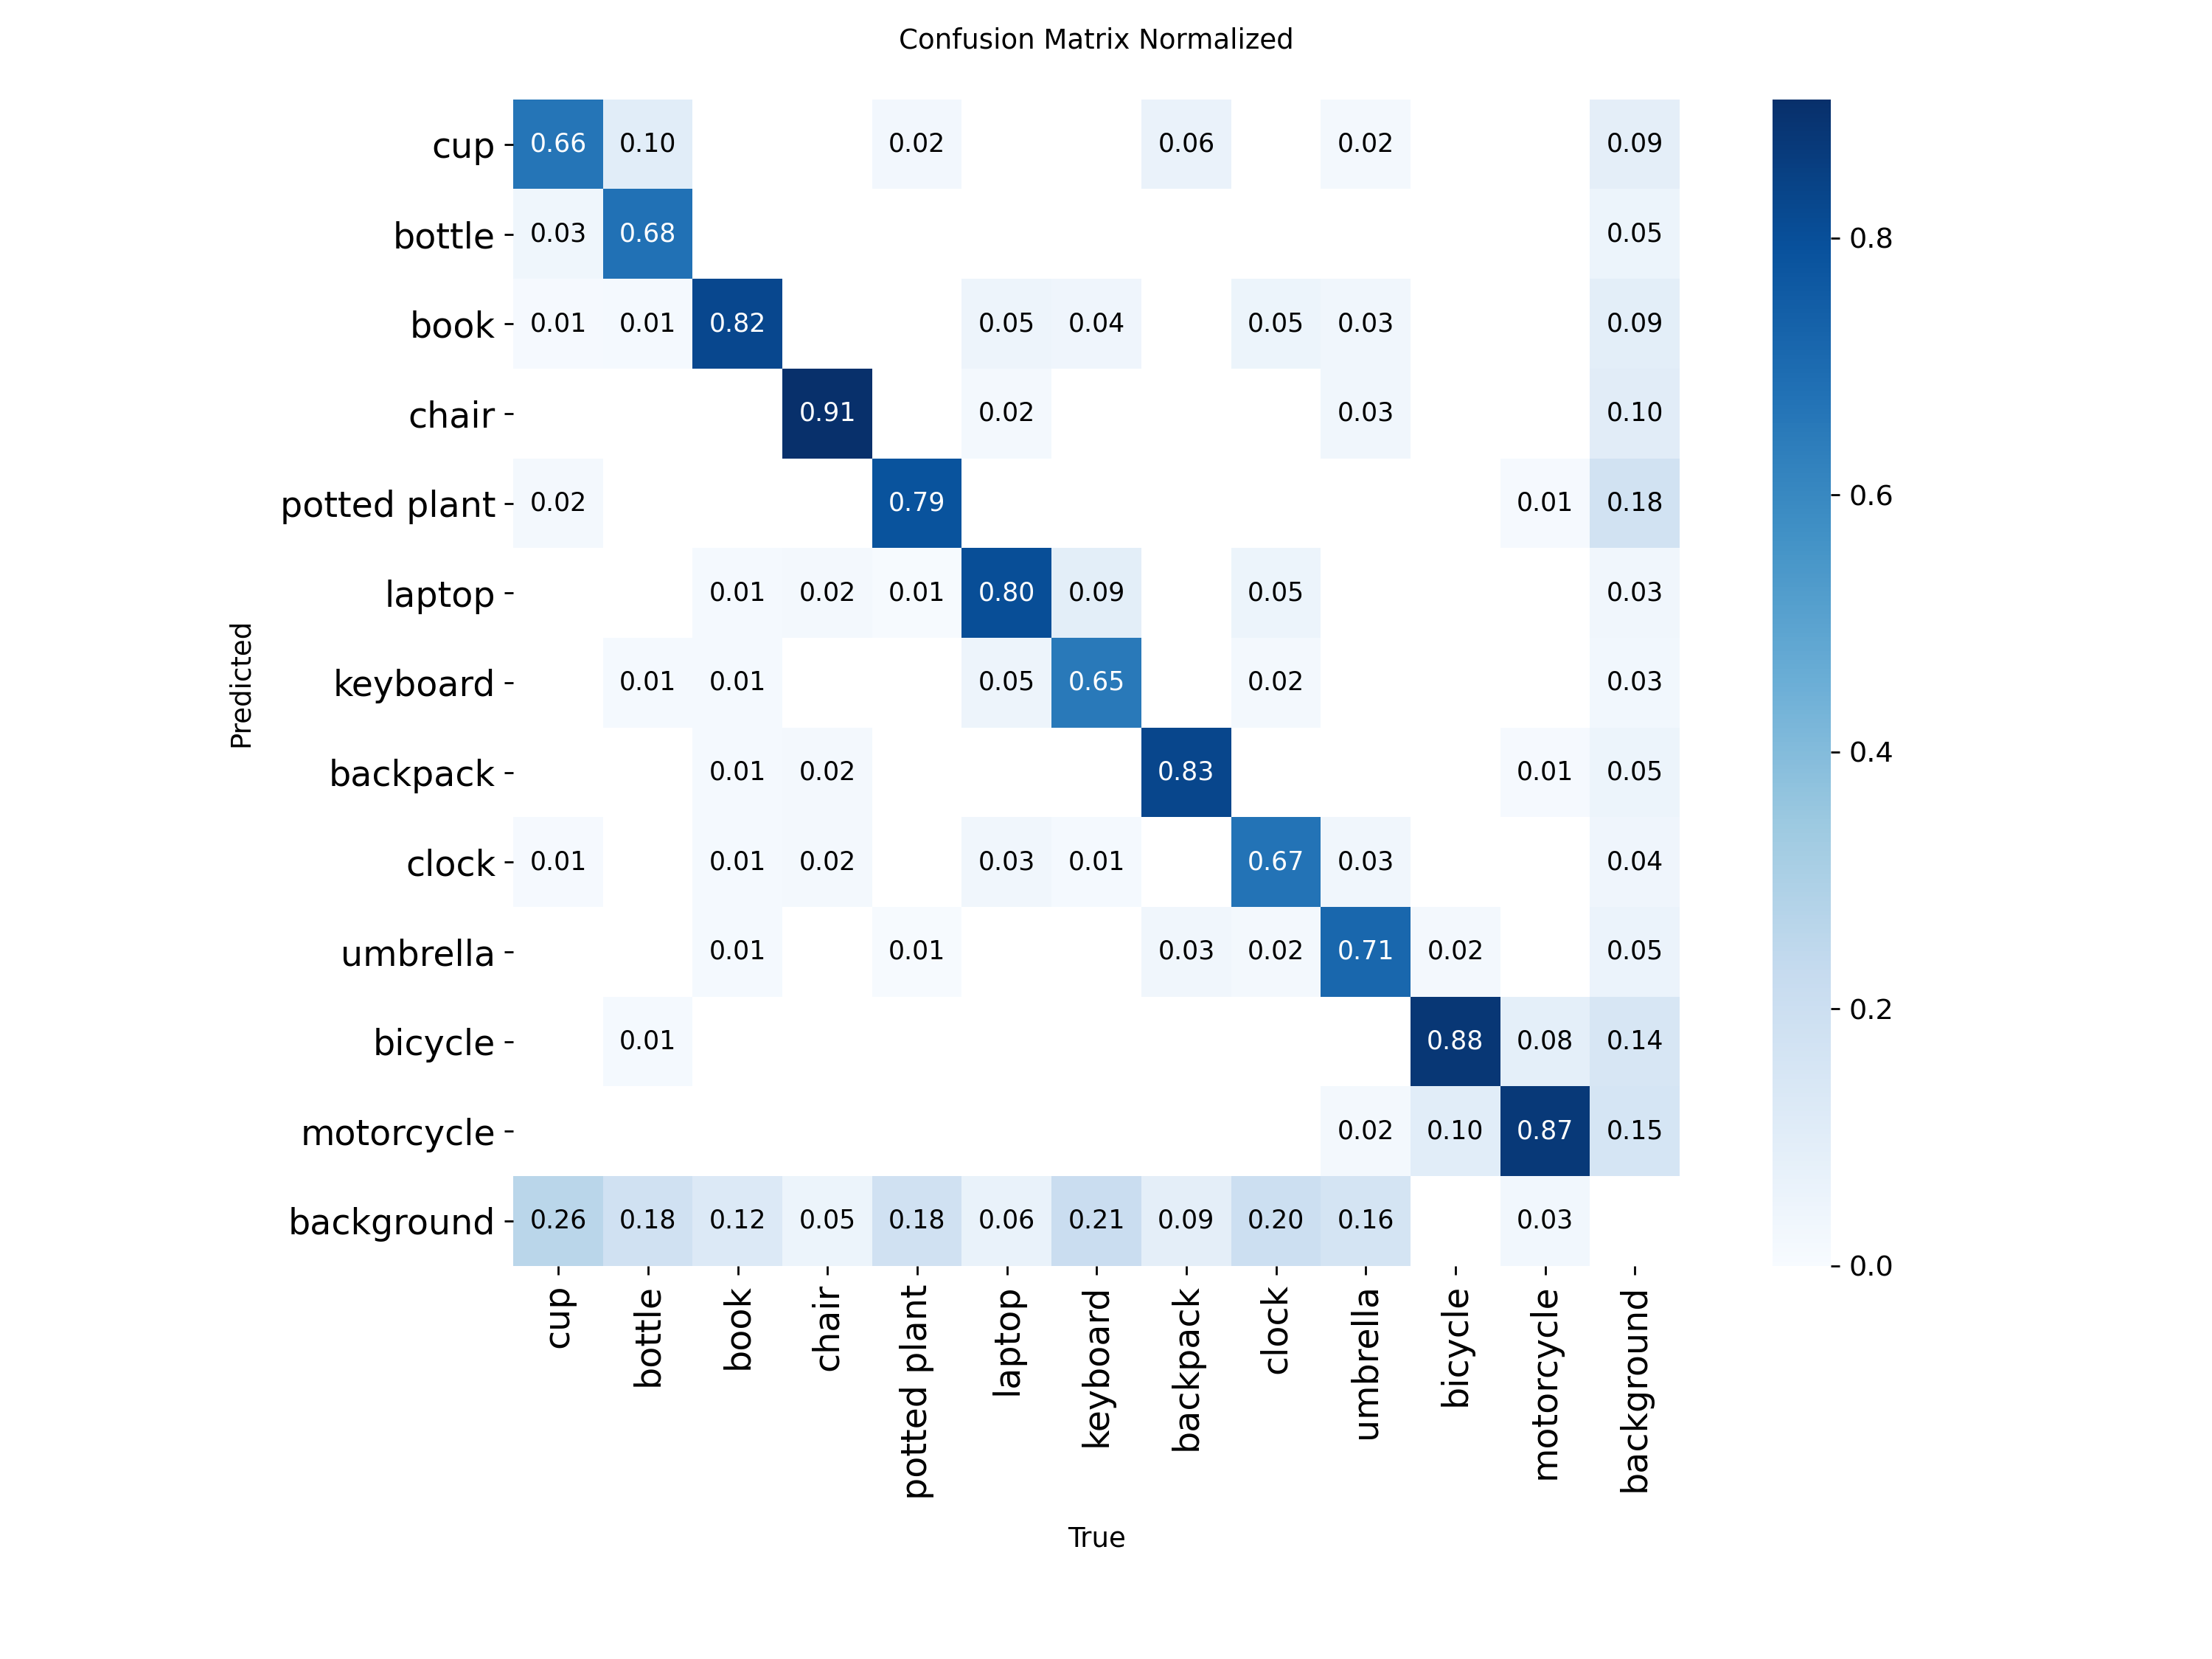

/content/drive/MyDrive/snapget-ml/artifacts/eval/y1-s/image_confusion_real_test.png


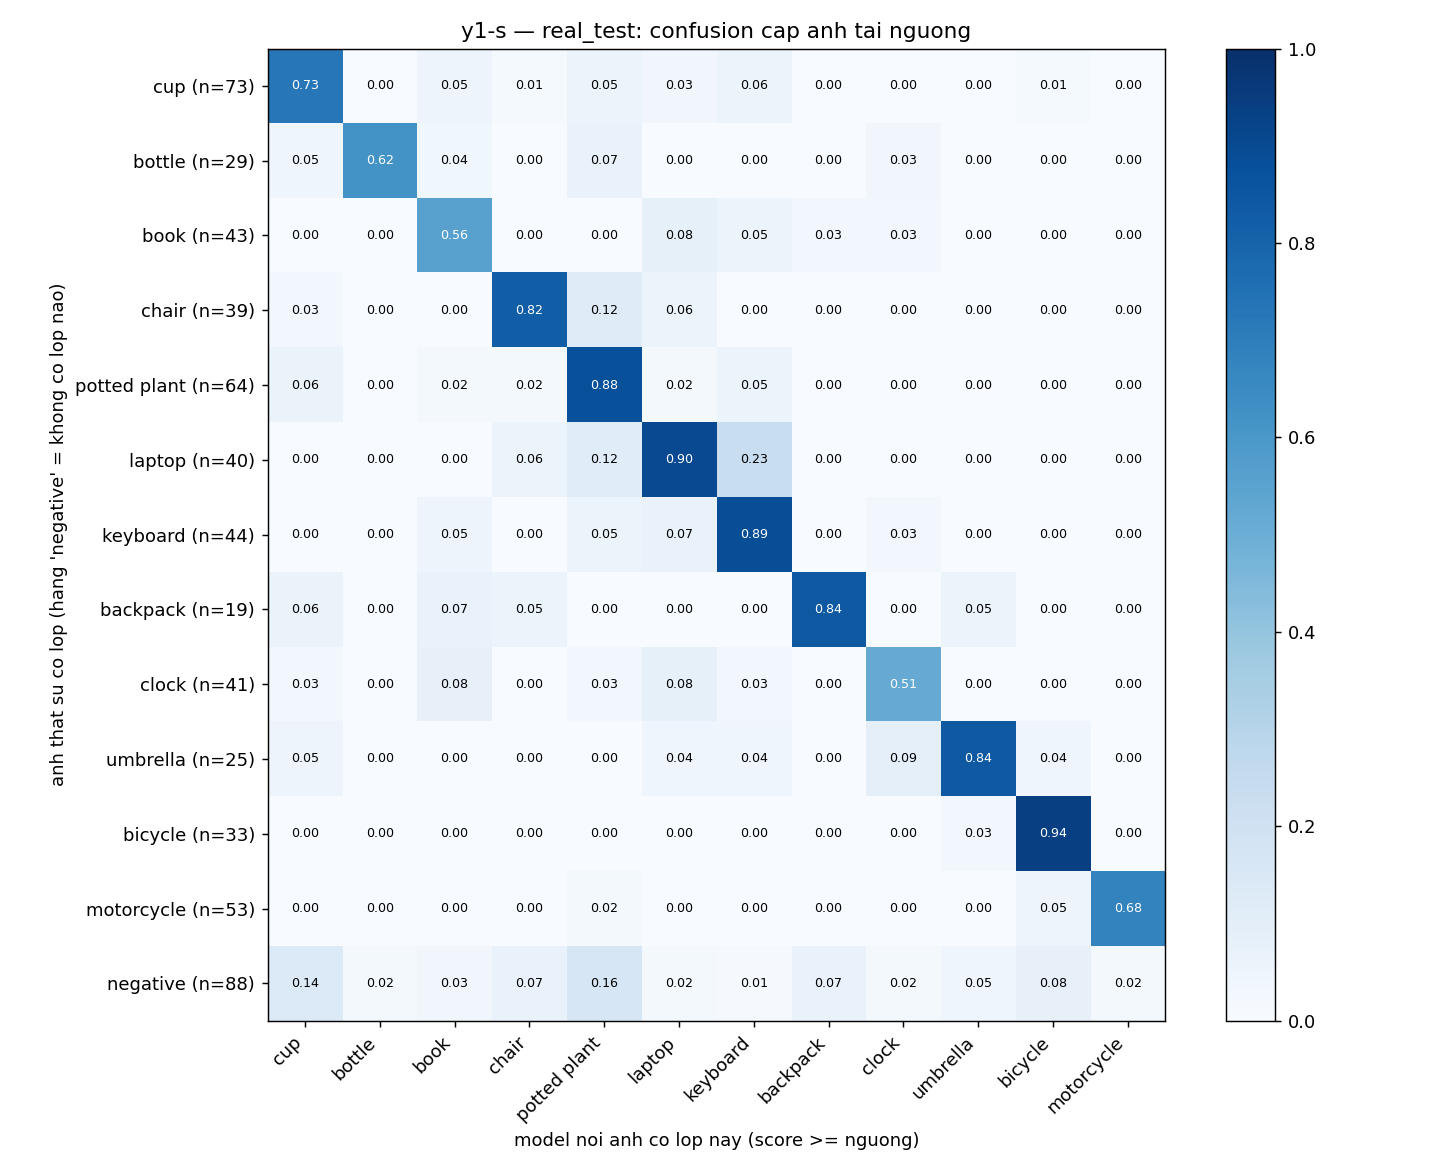

/content/drive/MyDrive/snapget-ml/artifacts/eval/y1-s/pr_curves_real_test.png


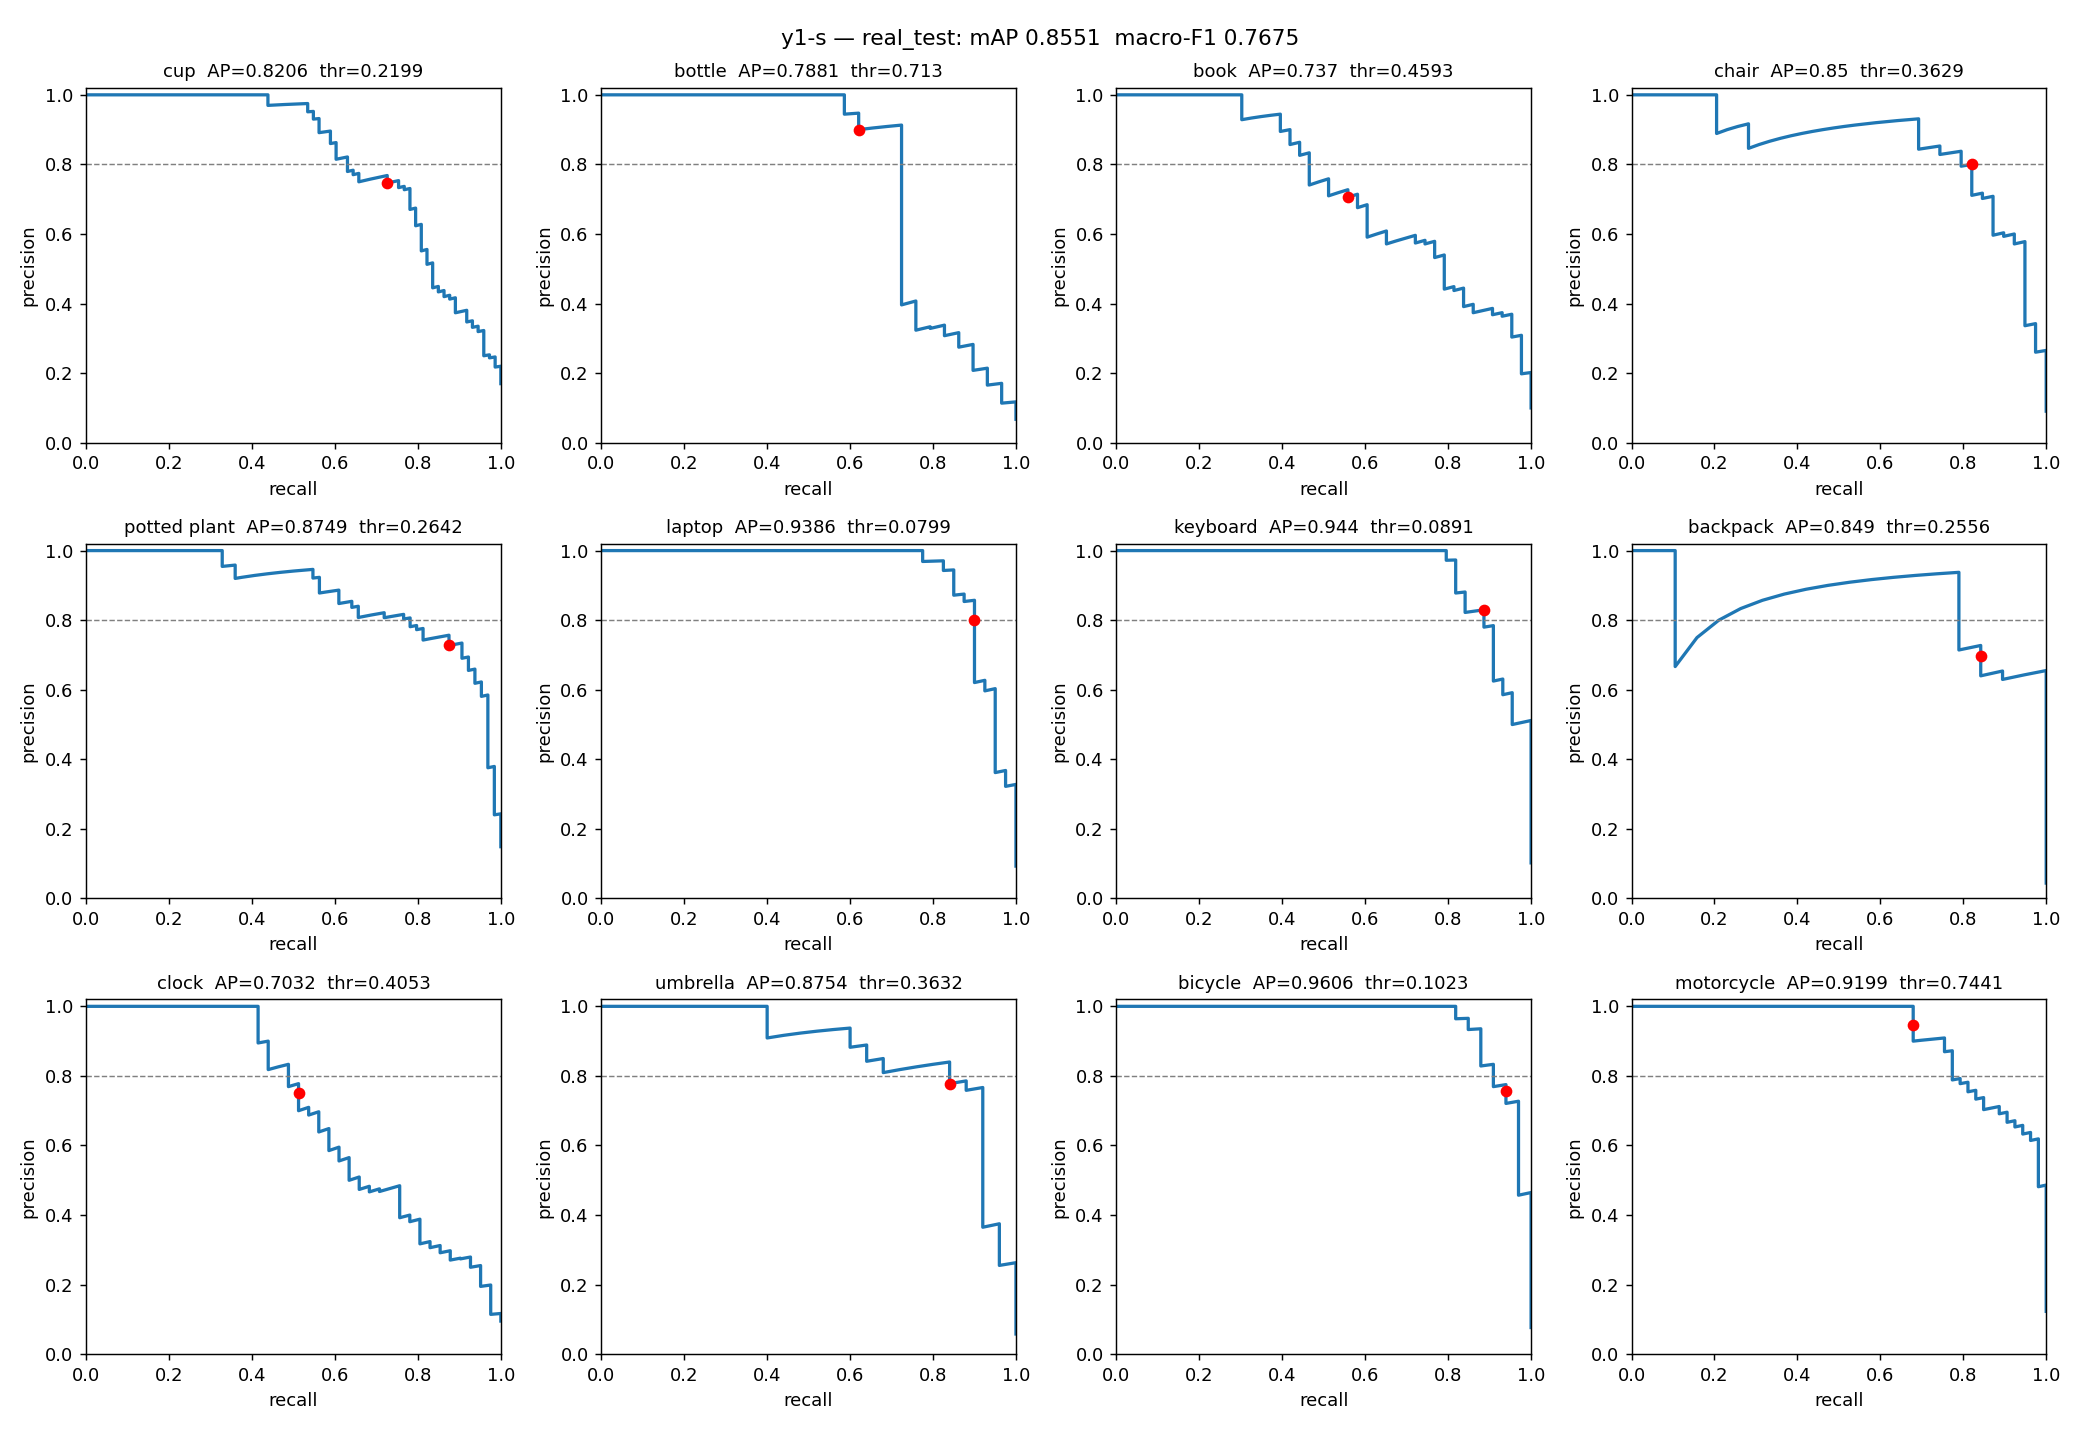

/content/drive/MyDrive/snapget-ml/artifacts/eval/y1-s/det_real_test/BoxF1_curve.png


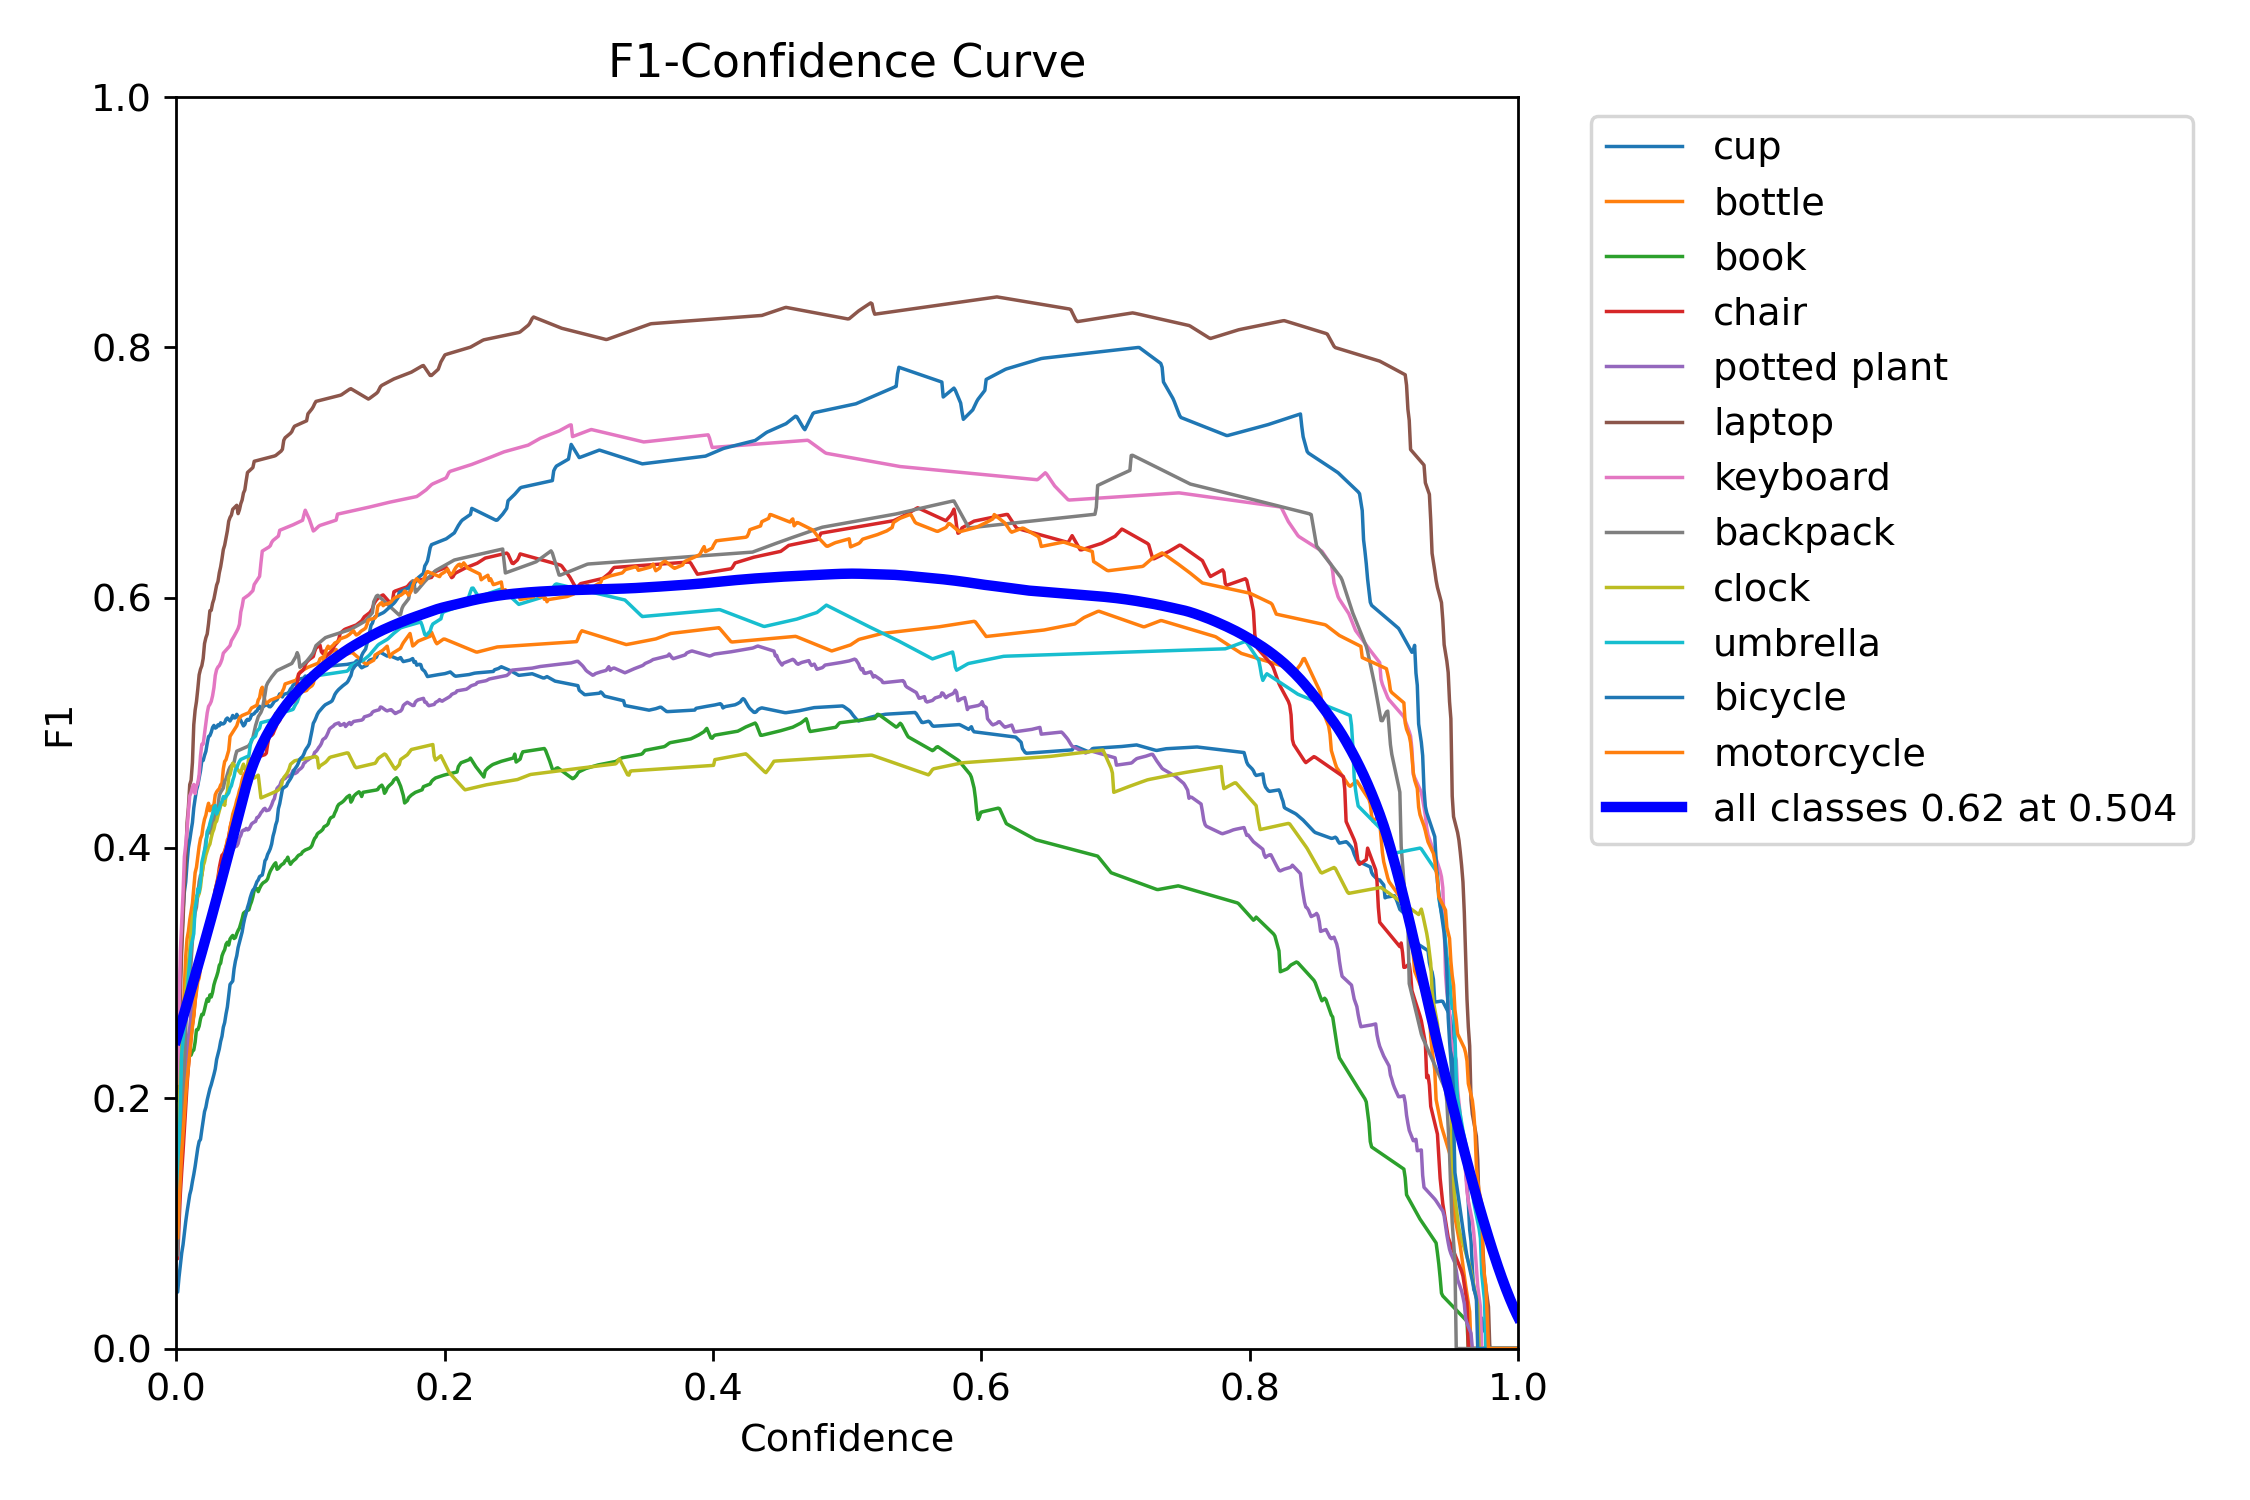

In [32]:
# Biểu đồ của y1-s: confusion matrix (detection), confusion cấp ảnh, PR curve, F1 curve
# (real_test nếu đã có ảnh tự chụp, không thì coco_test)
from IPython.display import Image, display
import os
EVAL = f'{WORK}/artifacts/eval/y1-s'
SPLIT = 'real_test' if os.path.exists(f'{EVAL}/metrics_real_test.json') else 'coco_test'
print('Tập:', SPLIT)
for p in [f'{EVAL}/det_{SPLIT}/confusion_matrix_normalized.png',
          f'{EVAL}/image_confusion_{SPLIT}.png',
          f'{EVAL}/pr_curves_{SPLIT}.png',
          f'{EVAL}/det_{SPLIT}/BoxF1_curve.png']:
    if os.path.exists(p):
        print(p); display(Image(p, width=900))

## 6. Chọn lớp ra đề quest
Một lớp chỉ được dùng làm quest khi đạt đủ các tiêu chí trên `real_test`:

| Tiêu chí | Ngưỡng |
|---|---|
| AP cấp ảnh | ≥ 0.85 |
| F1 tại ngưỡng | ≥ 0.85 |
| AP50 detection | ≥ 0.75 |
| Tỉ lệ từ chối sai | ≤ 15% |
| Bị lớp khác nhận nhầm | ≤ 5% |
| Số ảnh test | ≥ 20 |

In [33]:
import os
EVAL = f'{WORK}/artifacts/eval/y1-s'
SPLIT = 'real_test' if os.path.exists(f'{EVAL}/metrics_real_test.json') else 'coco_test'
if SPLIT != 'real_test':
    print('Chưa có real_test -> kết quả chọn lớp dưới đây là tạm thời (trên coco_test)')
!python scripts/15_select_classes.py --eval {EVAL} --split {SPLIT}
!cat {EVAL}/class_selection.md

# Chọn lớp ra đề quest — model `y1-s`, tập `real_test` (ngưỡng chọn trên `real_calib`)

Tiêu chí: AP ảnh ≥ 0.85 · F1 ≥ 0.85 · AP50 box ≥ 0.75 · từ chối sai ≤ 15% · bị nhầm ≤ 5% · ≥ 20 ảnh test.

| Lớp | Ảnh test | Ngưỡng | AP ảnh | F1 | P | R | Từ chối sai | AP50 box | Bị nhầm nhiều nhất bởi | Kết quả |
|---|---|---|---|---|---|---|---|---|---|---|
| cup | 73 | 0.220 | 0.821 | 0.736 | 0.747 | 0.726 | 27% | 0.500 | negative (14%) | ❌ AP ảnh, F1, AP50 box, Từ chối sai, Bị nhầm |
| bottle | 29 | 0.713 | 0.788 | 0.735 | 0.900 | 0.621 | 38% | 0.541 | negative (2%) | ❌ AP ảnh, F1, AP50 box, Từ chối sai |
| book | 43 | 0.459 | 0.737 | 0.623 | 0.706 | 0.558 | 44% | 0.465 | clock (8%) | ❌ AP ảnh, F1, AP50 box, Từ chối sai, Bị nhầm |
| chair | 39 | 0.363 | 0.850 | 0.810 | 0.800 | 0.821 | 18% | 0.649 | negative (7%) | ✅ RA ĐỀ |
| potted plant | 64 | 0.264 | 0.875 | 0.794 | 0.727 | 0.875 | 12% | 0.483 | negative (16%) | ✅ RA ĐỀ |
| laptop | 40 | 0.080 | 0.939 | 0.847 | 0.800 | 0.900 | 10% | 0.851 

## 7. Export ONNX và triển khai
Export ONNX fp32 (không lượng tử hoá int8 vì làm giảm độ chính xác), so khớp đầu ra với PyTorch, rồi tải `model.onnx`, `thresholds.json`, `model_meta.json` lên Hugging Face. AI service trên Cloud Run tải model từ đó khi khởi động; sau khi restart, `/health` trả về `modelVersion: "y1"`, `arch: "yolo"`.

In [ ]:
from huggingface_hub import login
login()
MODEL_REPO = 'Flowerng/snapget-ai-model'
!python scripts/16_export_yolo_onnx.py --weights {WORK}/artifacts/y1-s/best.pt \
    --thresholds {WORK}/artifacts/eval/y1-s/thresholds.json --version y1 --out {WORK}/artifacts/y1-s/export \
    --upload {MODEL_REPO}

## 8. Tổng hợp
So sánh các model trên từng tập: mAP cấp ảnh, macro-F1, mAP50 / mAP50-95 detection và độ trễ trung vị trên CPU.

In [ ]:
import json
rows = json.load(open(f'{WORK}/artifacts/eval/ablation.json'))
f = lambda v: '-' if v is None else (f'{v:.3f}' if isinstance(v, float) else str(v))
print(f"{'model':14s} {'split':10s} {'n':>5s} {'mAP ảnh':>8s} {'macroF1':>8s} {'AP50 box':>9s} {'AP50-95':>8s} {'p50 ms':>7s}")
for r in rows:
    print(f"{r['model']:14s} {r['split']:10s} {r['n']:5d} {f(r['imageMAP']):>8s} {f(r['macroF1']):>8s} "
          f"{f(r['detMAP50']):>9s} {f(r['detMAP50_95']):>8s} {f(r['latencyP50ms']):>7s}")